# 04 Exploratory Analysis
This notebook will load the compiled parquets from `03_feature_engineering.ipynb` and do the following:
1. Calculate correlation between key features from `tlc_hourly_final` and analyse by group
    - by-borough analysis for how `n_trips` (taxi and fhvhv), `avg_wait_time` (fhvhv), and `ridership` (mta) changes with alert level
2. Geo-spatial visualisations of various aspects of the data using `geopandas` 
    - `n_trips_taxi` and `n_trips_fhvhv` in each zone, summed over the given time range
    - `n_stations` in each zone 
    - `n_alerts` in each zone, summed over the given time range by each `borough`
    - `ridership` in each zone, summed over the given time range 
3. Temporal visualisations of various aspects of the data 
    - `n_alerts` hourly (total over the given time range) by each `borough`
    - `ridership` hourly (total over the given time range) by each `borough`


In [1]:
# Restart spark if required
try:
    spark.stop()
except NameError:
    pass
except Exception:
    pass

from pyspark.sql import SparkSession

# Create a spark session (which will run spark jobs)
spark = (
    SparkSession.builder.appName("MAST30034 Project 1")
    .config("spark.sql.repl.eagerEval.enabled", True) 
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "America/New_York") # timezone set to NYC
    .getOrCreate()
)
spark.conf.set("spark.sql.shuffle.partitions", "800")
spark.conf.set("spark.sql.adaptive.enabled", "true")

spark.sparkContext.setLogLevel("ERROR") # silence warnings

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/15 17:39:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Set up and configuration

In [2]:
# Imports
from pathlib import Path
from pyspark.sql import functions as F
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler

In [3]:
# Raw spatial data from `01_fetch_data.ipynb`
taxi_zones_path = "../data/raw/taxi_zones/taxi_zones.shp"

# Input directories from `02_preprocess_data.ipynb`
processed_dir = "../data/processed"

yellow_path = f"{processed_dir}/tlc_trips/yellow"
green_path = f"{processed_dir}/tlc_trips/green"
fhvhv_path = f"{processed_dir}/tlc_trips/fhvhv"
ridership_path = f"{processed_dir}/mta_ridership"
alerts_path = f"{processed_dir}/mta_alerts"
weather_path = f"{processed_dir}/meteostat_weather"

# Input directories from `03_feature_engineering.ipynb`
features_dir = "../data/features"

# Output directories for `04_exploratory_analysis.ipynb`
analysis_dir = "../data/analysis"

In [4]:
# Helper function: prints shape of sdf
def spark_shape(sdf):
    return (sdf.count(), len(sdf.columns))

# Helper function: save a sdf as parquet
def save_sdf(sdf, name):
    path = f"{analysis_dir}/{name}"
    sdf.write.mode("overwrite").parquet(path)
    print(f"Saved {name} to {path}")

# Helper function: read a sdf from parquet
def read_sdf(name):
    return spark.read.parquet(f"{analysis_dir}/{name}")

In [5]:
sdf_tlc_hourly = spark.read.parquet(f"{features_dir}/tlc_zone_hourly_final")

## Correlation analysis

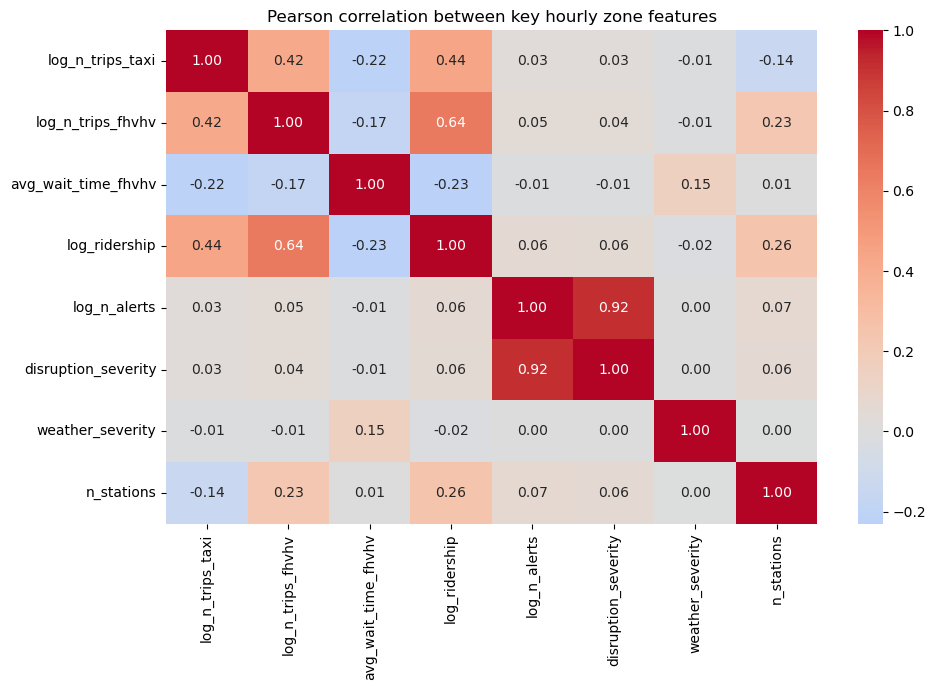

In [6]:
# Build initial correlation matrix for all features in `sdf_tlc_hourly`
corr_df = (
    sdf_tlc_hourly
    .withColumn("log_n_trips_taxi", F.log1p("n_trips_taxi"))
    .withColumn("log_n_trips_fhvhv", F.log1p("n_trips_fhvhv"))
    .withColumn("log_gross_fare_taxi", F.log1p("gross_fare_taxi"))
    .withColumn("log_gross_fare_fhvhv", F.log1p("gross_fare_fhvhv"))
    .withColumn("log_ridership", F.log1p("ridership"))
    .withColumn("log_n_alerts", F.log1p("n_alerts"))
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
    .withColumn("has_severe_disruption", (F.col("disruption_severity") >= 3).cast("int"))
)
corr_cols = [
    "log_n_trips_taxi",
    "log_n_trips_fhvhv",
    "avg_wait_time_fhvhv",
    "log_ridership",
    "log_n_alerts",
    "disruption_severity",
    "weather_severity",
    "n_stations",
]

corr_pd = corr_df.select(corr_cols).toPandas()
corr_matrix = corr_pd.corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Pearson correlation between key hourly zone features")
plt.tight_layout()
plt.show()

## TLC trips, wait time, and MTA ridership 
Visualised by borough and by weekday/weekend

+-----------+------------+------------------+-------------------+------------------+------------------+
|alert_level|n_zone_hours|avg_taxi_trip_lift|avg_fhvhv_trip_lift|avg_wait_time_lift|avg_ridership_lift|
+-----------+------------+------------------+-------------------+------------------+------------------+
|0_no_alert |1827424     |-1.0E-4           |-1.0E-4            |1.0E-4            |0.0018            |
|1_low      |31047       |0.5004            |1.7866             |1.287             |13.1062           |
|2_medium   |14770       |0.6048            |2.4816             |2.907             |27.3148           |
|3_high     |4305        |0.4792            |0.4781             |11.824            |-8.7161           |
+-----------+------------+------------------+-------------------+------------------+------------------+



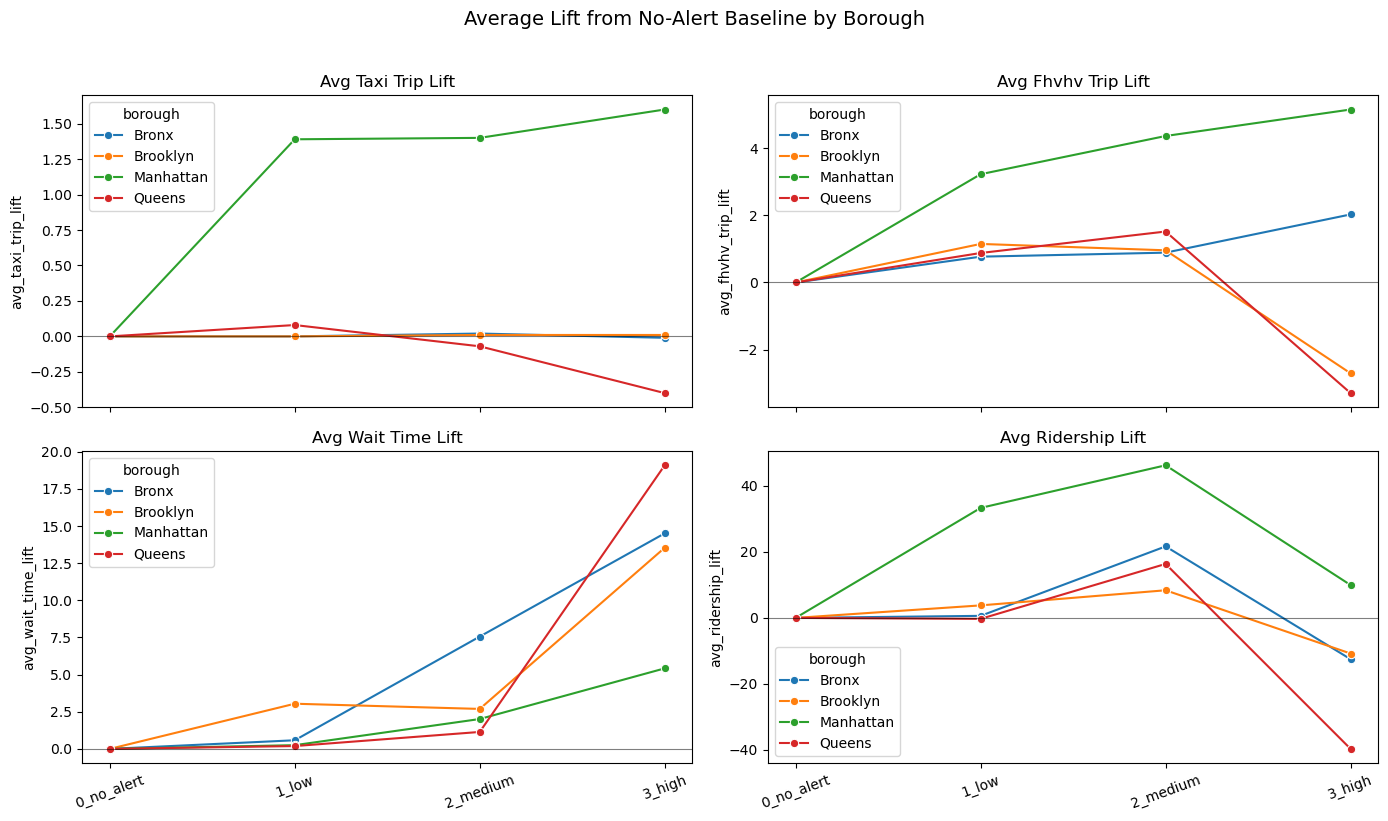

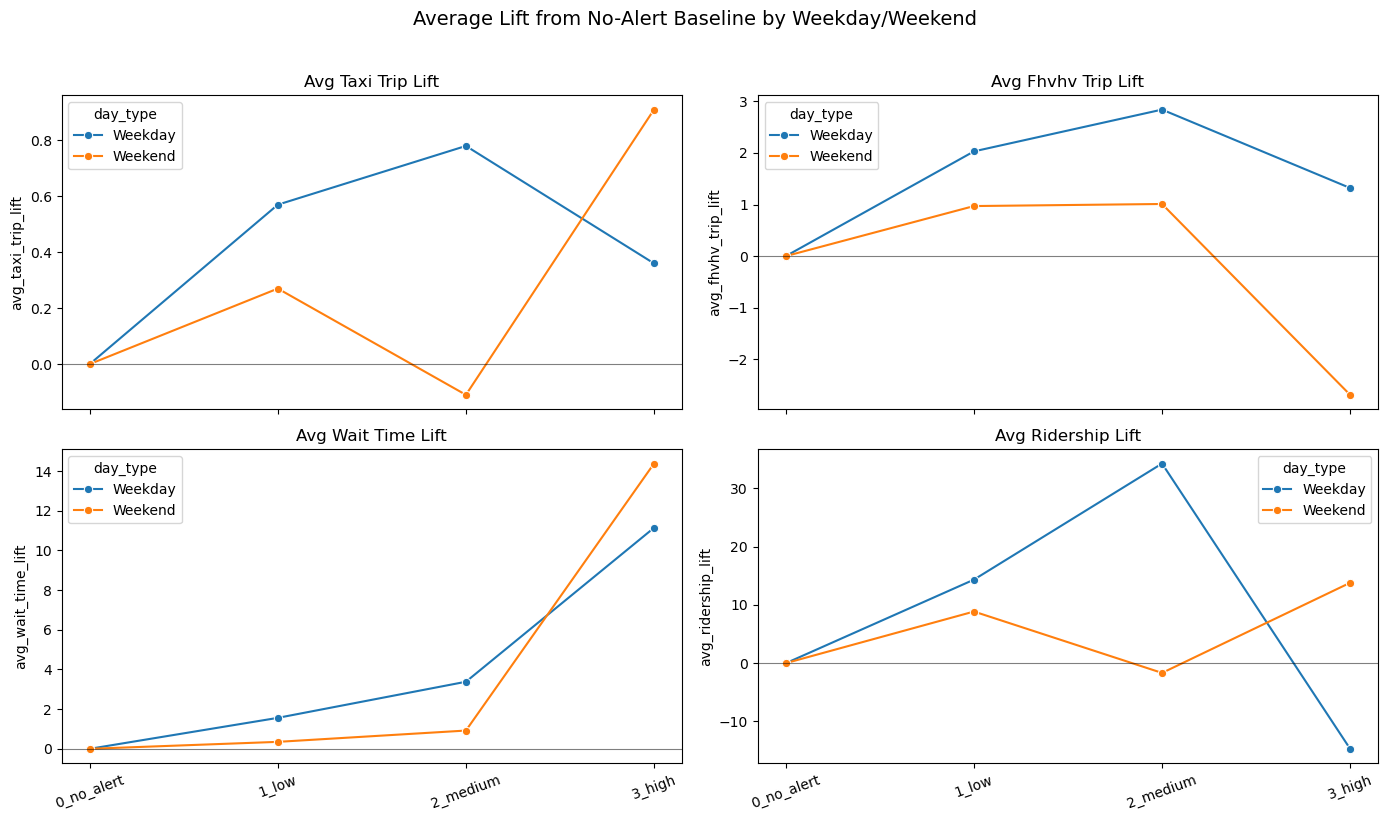

In [7]:
# -------------------------------------------------------------------
# 1. Build analysis table
# -------------------------------------------------------------------

analysis_df = (
    sdf_tlc_hourly
    .withColumn("hour_of_day", F.hour("hour"))
    .withColumn(
        "day_type",
        F.when(F.dayofweek("hour").isin([1, 7]), "Weekend")
         .otherwise("Weekday")
    )
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
)

# -------------------------------------------------------------------
# 2. Build no-alert baseline
# Baseline is calculated separately for each:
# zone + hour of day + weekday/weekend type
# -------------------------------------------------------------------

baseline_df = (
    analysis_df
    .filter(F.col("has_alert") == 0)
    .groupBy("PULocationID", "hour_of_day", "day_type")
    .agg(
        F.avg("n_trips_taxi").alias("baseline_n_trips_taxi"),
        F.avg("n_trips_fhvhv").alias("baseline_n_trips_fhvhv"),
        F.avg("avg_wait_time_fhvhv").alias("baseline_avg_wait_time_fhvhv"),
        F.avg("ridership").alias("baseline_ridership"),
    )
)

# -------------------------------------------------------------------
# 3. Compare every zone-hour against its no-alert baseline
# -------------------------------------------------------------------

alert_effect_df = (
    analysis_df
    .join(
        baseline_df,
        on=["PULocationID", "hour_of_day", "day_type"],
        how="left"
    )

    # Absolute lift: observed minus no-alert baseline
    .withColumn("taxi_trip_lift", F.col("n_trips_taxi") - F.col("baseline_n_trips_taxi"))
    .withColumn("fhvhv_trip_lift", F.col("n_trips_fhvhv") - F.col("baseline_n_trips_fhvhv"))
    .withColumn("wait_time_lift", F.col("avg_wait_time_fhvhv") - F.col("baseline_avg_wait_time_fhvhv"))
    .withColumn("ridership_lift", F.col("ridership") - F.col("baseline_ridership"))

    # Ratio lift: observed divided by no-alert baseline
    .withColumn("taxi_trip_ratio",
        F.when(
            F.col("baseline_n_trips_taxi") > 0,
            F.col("n_trips_taxi") / F.col("baseline_n_trips_taxi")
        )
    )
    .withColumn("fhvhv_trip_ratio",
        F.when(
            F.col("baseline_n_trips_fhvhv") > 0,
            F.col("n_trips_fhvhv") / F.col("baseline_n_trips_fhvhv")
        )
    )
    .withColumn("wait_time_ratio",
        F.when(
            F.col("baseline_avg_wait_time_fhvhv") > 0,
            F.col("avg_wait_time_fhvhv") / F.col("baseline_avg_wait_time_fhvhv")
        )
    )
    .withColumn("ridership_ratio",
        F.when(
            F.col("baseline_ridership") > 0,
            F.col("ridership") / F.col("baseline_ridership")
        )
    )

    # Alert categories
    .withColumn("alert_level",
        F.when(F.col("disruption_severity") == 0, "0_no_alert")
         .when(F.col("disruption_severity") == 1, "1_low")
         .when(F.col("disruption_severity") == 2, "2_medium")
         .otherwise("3_high")
    )

    # Average severity per distinct alert
    .withColumn("avg_severity_per_alert",
        F.when(
            F.col("n_alerts") > 0,
            F.col("disruption_severity") / F.col("n_alerts")
        ).otherwise(0)
    )
)

# -------------------------------------------------------------------
# 4. Sanity check: no-alert average lifts should be close to 0
# -------------------------------------------------------------------

sanity_check = (
    alert_effect_df
    .groupBy("alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("taxi_trip_lift"), 4).alias("avg_taxi_trip_lift"),
        F.round(F.avg("fhvhv_trip_lift"), 4).alias("avg_fhvhv_trip_lift"),
        F.round(F.avg("wait_time_lift"), 4).alias("avg_wait_time_lift"),
        F.round(F.avg("ridership_lift"), 4).alias("avg_ridership_lift"),
    )
    .orderBy("alert_level")
)

sanity_check.show(truncate=False)

# -------------------------------------------------------------------
# 5. By-borough summary
# -------------------------------------------------------------------

borough_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 2).alias("avg_taxi_trips"),
        F.round(F.avg("n_trips_fhvhv"), 2).alias("avg_fhvhv_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 2).alias("baseline_taxi_trips"),
        F.round(F.avg("baseline_n_trips_fhvhv"), 2).alias("baseline_fhvhv_trips"),
        F.round(F.avg("taxi_trip_lift"), 2).alias("avg_taxi_trip_lift"),
        F.round(F.avg("fhvhv_trip_lift"), 2).alias("avg_fhvhv_trip_lift"),
        F.round(F.avg("wait_time_lift"), 2).alias("avg_wait_time_lift"),
        F.round(F.avg("ridership_lift"), 2).alias("avg_ridership_lift"),
    )
    .orderBy("borough", "alert_level")
)

borough_summary_pd = borough_summary.toPandas()

# -------------------------------------------------------------------
# 6. Weekday/weekend summary
# -------------------------------------------------------------------

day_type_summary = (
    alert_effect_df
    .groupBy("day_type", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 2).alias("avg_taxi_trips"),
        F.round(F.avg("n_trips_fhvhv"), 2).alias("avg_fhvhv_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 2).alias("baseline_taxi_trips"),
        F.round(F.avg("baseline_n_trips_fhvhv"), 2).alias("baseline_fhvhv_trips"),
        F.round(F.avg("taxi_trip_lift"), 2).alias("avg_taxi_trip_lift"),
        F.round(F.avg("fhvhv_trip_lift"), 2).alias("avg_fhvhv_trip_lift"),
        F.round(F.avg("wait_time_lift"), 2).alias("avg_wait_time_lift"),
        F.round(F.avg("ridership_lift"), 2).alias("avg_ridership_lift"),
    )
    .orderBy("day_type", "alert_level")
)

day_type_summary_pd = day_type_summary.toPandas()

# -------------------------------------------------------------------
# 7. Ensure alert levels are plotted in correct order
# -------------------------------------------------------------------

alert_order = ["0_no_alert", "1_low", "2_medium", "3_high"]

for pdf in [borough_summary_pd, day_type_summary_pd]:
    pdf["alert_level"] = pd.Categorical(
        pdf["alert_level"],
        categories=alert_order,
        ordered=True
    )
    pdf.sort_values("alert_level", inplace=True)

# -------------------------------------------------------------------
# 8. Plot helper
# -------------------------------------------------------------------

def plot_alert_lifts(summary_pd, hue_col, title_prefix):
    metrics = [
        "avg_taxi_trip_lift",
        "avg_fhvhv_trip_lift",
        "avg_wait_time_lift",
        "avg_ridership_lift",
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

    for ax, metric in zip(axes.flatten(), metrics):
        sns.lineplot(
            data=summary_pd,
            x="alert_level",
            y=metric,
            hue=hue_col,
            marker="o",
            ax=ax
        )
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
        ax.set_title(metric.replace("_", " ").title())
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=20)

    fig.suptitle(title_prefix, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# -------------------------------------------------------------------
# 9. Plots
# -------------------------------------------------------------------

plot_alert_lifts(
    borough_summary_pd,
    hue_col="borough",
    title_prefix="Average Lift from No-Alert Baseline by Borough"
)

plot_alert_lifts(
    day_type_summary_pd,
    hue_col="day_type",
    title_prefix="Average Lift from No-Alert Baseline by Weekday/Weekend"
)

In [8]:
# Create grouped effect summary (per borough) with avg and std
grouped_effect_summary = (
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),

        F.avg("taxi_trip_lift").alias("avg_taxi_trip_lift"),
        F.stddev("taxi_trip_lift").alias("sd_taxi_trip_lift"),

        F.avg("fhvhv_trip_lift").alias("avg_fhvhv_trip_lift"),
        F.stddev("fhvhv_trip_lift").alias("sd_fhvhv_trip_lift"),

        F.avg("wait_time_lift").alias("avg_wait_time_lift"),
        F.stddev("wait_time_lift").alias("sd_wait_time_lift"),

        F.avg("ridership_lift").alias("avg_ridership_lift"),
        F.stddev("ridership_lift").alias("sd_ridership_lift"),
    )
    .withColumn(
        "ci95_taxi_trip_lift",
        1.96 * F.col("sd_taxi_trip_lift") / F.sqrt(F.col("n_zone_hours"))
    )
    .withColumn(
        "ci95_fhvhv_trip_lift",
        1.96 * F.col("sd_fhvhv_trip_lift") / F.sqrt(F.col("n_zone_hours"))
    )
    .withColumn(
        "ci95_wait_time_lift",
        1.96 * F.col("sd_wait_time_lift") / F.sqrt(F.col("n_zone_hours"))
    )
)

# Round averages and standard deviations
grouped_effect_summary = grouped_effect_summary.select(
    "borough",
    "alert_level",
    "n_zone_hours",
    *[
        F.round(F.col(c), 3).alias(c)
        for c in grouped_effect_summary.columns
        if c not in ["borough", "alert_level", "n_zone_hours"]
    ]
).orderBy("borough", "alert_level")

grouped_effect_summary.show(truncate=False)

+---------+-----------+------------+------------------+-----------------+-------------------+------------------+------------------+-----------------+------------------+-----------------+-------------------+--------------------+-------------------+
|borough  |alert_level|n_zone_hours|avg_taxi_trip_lift|sd_taxi_trip_lift|avg_fhvhv_trip_lift|sd_fhvhv_trip_lift|avg_wait_time_lift|sd_wait_time_lift|avg_ridership_lift|sd_ridership_lift|ci95_taxi_trip_lift|ci95_fhvhv_trip_lift|ci95_wait_time_lift|
+---------+-----------+------------+------------------+-----------------+-------------------+------------------+------------------+-----------------+------------------+-----------------+-------------------+--------------------+-------------------+
|Bronx    |0_no_alert |339983      |0.0               |0.279            |0.001              |24.074            |0.002             |66.724           |-0.001            |199.296          |0.001              |0.081               |0.224              |
|Bronx  

In [9]:
summary_pd = grouped_effect_summary.toPandas()

borough_palette = {
    "Bronx": "#1f77b4",
    "Brooklyn": "#ff7f0e",
    "Manhattan": "#2ca02c",
    "Queens": "#d62728",
}

alert_order = ["0_no_alert", "1_low", "2_medium", "3_high"]
borough_order = ["Bronx", "Brooklyn", "Manhattan", "Queens"]

summary_pd = grouped_effect_summary.toPandas()
summary_pd["alert_level"] = pd.Categorical(
    summary_pd["alert_level"],
    categories=alert_order,
    ordered=True
)
summary_pd["borough"] = pd.Categorical(
    summary_pd["borough"],
    categories=borough_order,
    ordered=True
)
summary_pd = summary_pd.sort_values(["borough", "alert_level"])

In [10]:
def plot_borough_ci(
    metric,
    ci_metric,
    title,
    ylabel,
    label_points=True,
    label_ci=True,
    ylim_pad_frac=0.18
):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(9.5, 6.2),
        dpi=160,
        sharex=True,
        sharey=True
    )

    # Global y-limits with padding so labels do not hit plot borders
    y_all = summary_pd[metric].to_numpy()
    ci_all = summary_pd[ci_metric].to_numpy()
    y_low = (y_all - ci_all).min()
    y_high = (y_all + ci_all).max()
    y_range = y_high - y_low

    if y_range == 0:
        y_range = 1

    y_min = y_low - ylim_pad_frac * y_range
    y_max = y_high + ylim_pad_frac * y_range

    for ax, borough in zip(axes.flatten(), borough_order):
        sub = summary_pd[summary_pd["borough"] == borough].sort_values("alert_level")
        x = list(range(len(sub)))
        y = sub[metric].to_numpy()
        yerr = sub[ci_metric].to_numpy()
        color = borough_palette[borough]

        ax.errorbar(
            x=x,
            y=y,
            yerr=yerr,
            marker="o",
            markersize=4,
            linewidth=1.8,
            capsize=3,
            color=color,
            ecolor=color,
            alpha=0.95
        )

        if label_points:
            for xi, yi, ei in zip(x, y, yerr):
                if label_ci:
                    label = f"{yi:.2f}\n±{ei:.2f}"
                else:
                    label = f"{yi:.2f}"

                # Put positive values above the CI bar and negative values below it
                text_offset = 0.035 * y_range
                if yi >= 0:
                    label_y = yi + ei + text_offset
                    va = "bottom"
                else:
                    label_y = yi - ei - text_offset
                    va = "top"

                ax.text(
                    xi,
                    label_y,
                    label,
                    ha="center",
                    va=va,
                    fontsize=6.5,
                    color=color,
                    linespacing=0.9
                )

        ax.axhline(0, color="0.45", linewidth=0.8)
        ax.set_ylim(y_min, y_max)
        ax.set_title(borough, fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(alert_order, rotation=20, ha="right", fontsize=8)
        ax.tick_params(axis="y", labelsize=8)
        ax.grid(axis="y", alpha=0.18)

    fig.suptitle(title, fontsize=12, y=1.02)
    fig.supxlabel("Alert severity", fontsize=10)
    fig.supylabel(ylabel, fontsize=10)
    plt.tight_layout()
    plt.show()

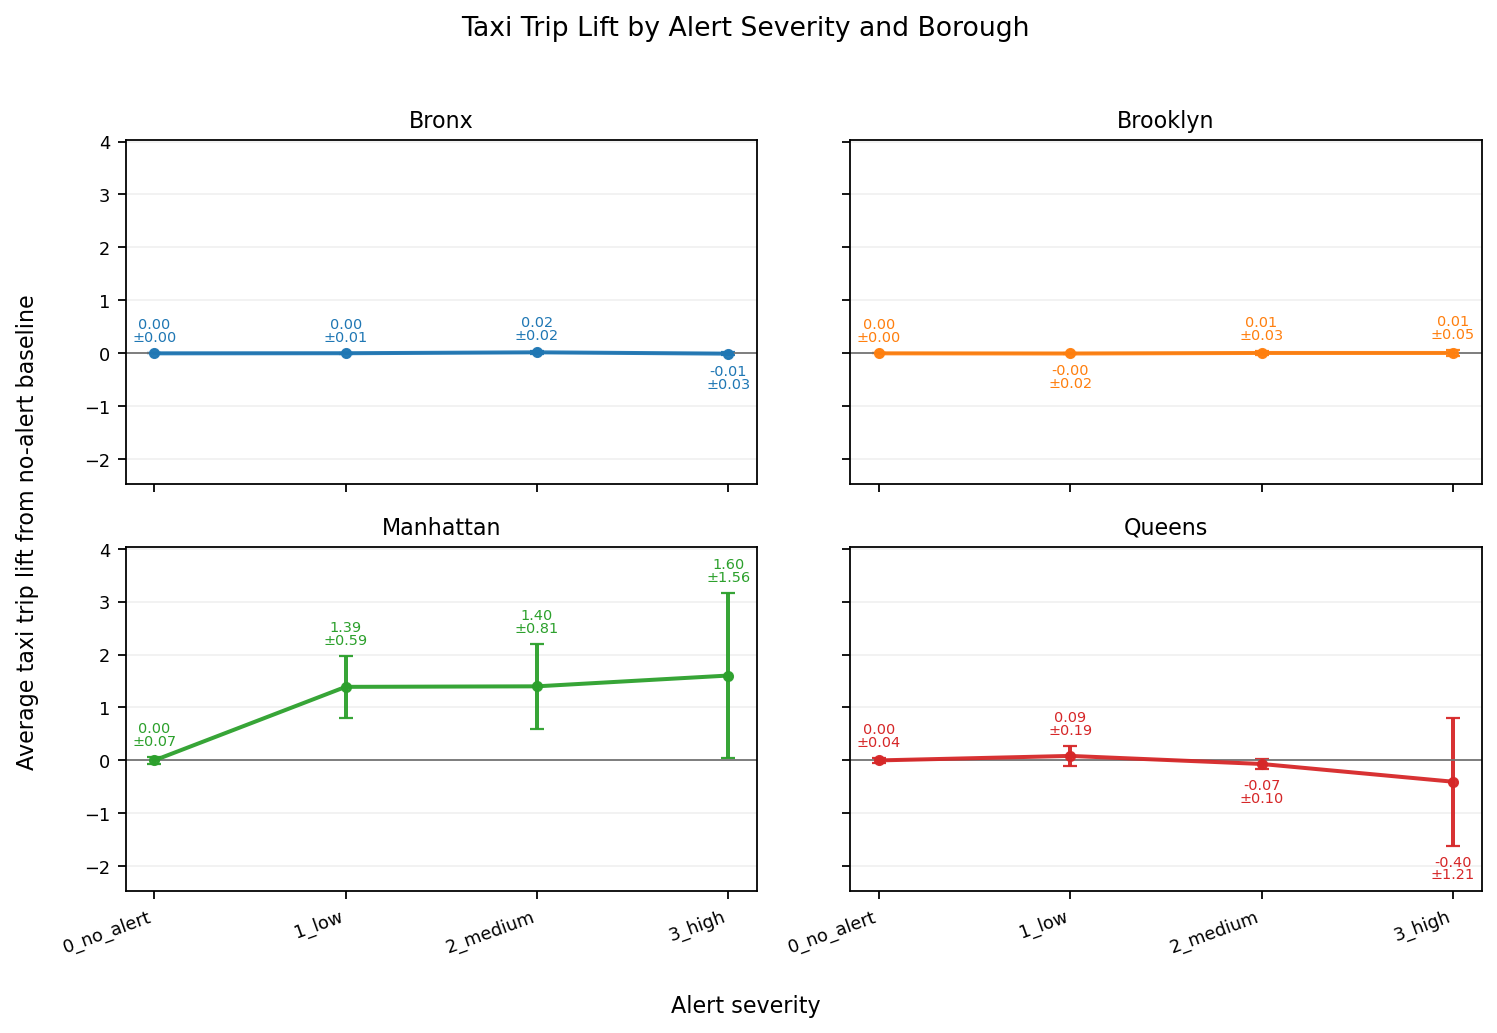

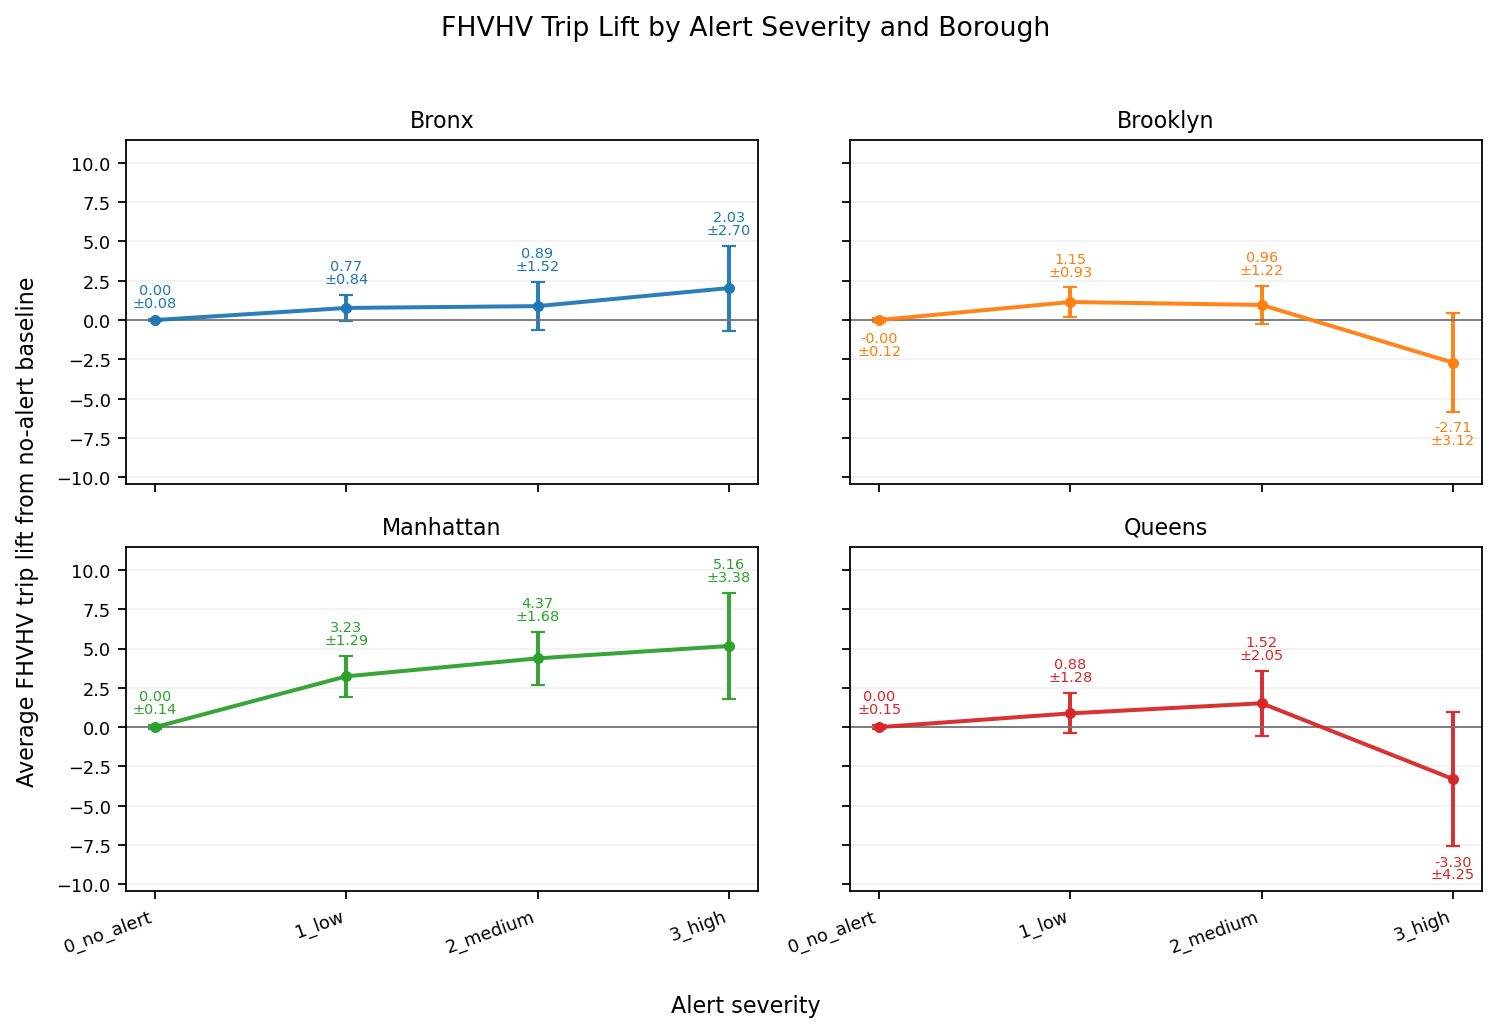

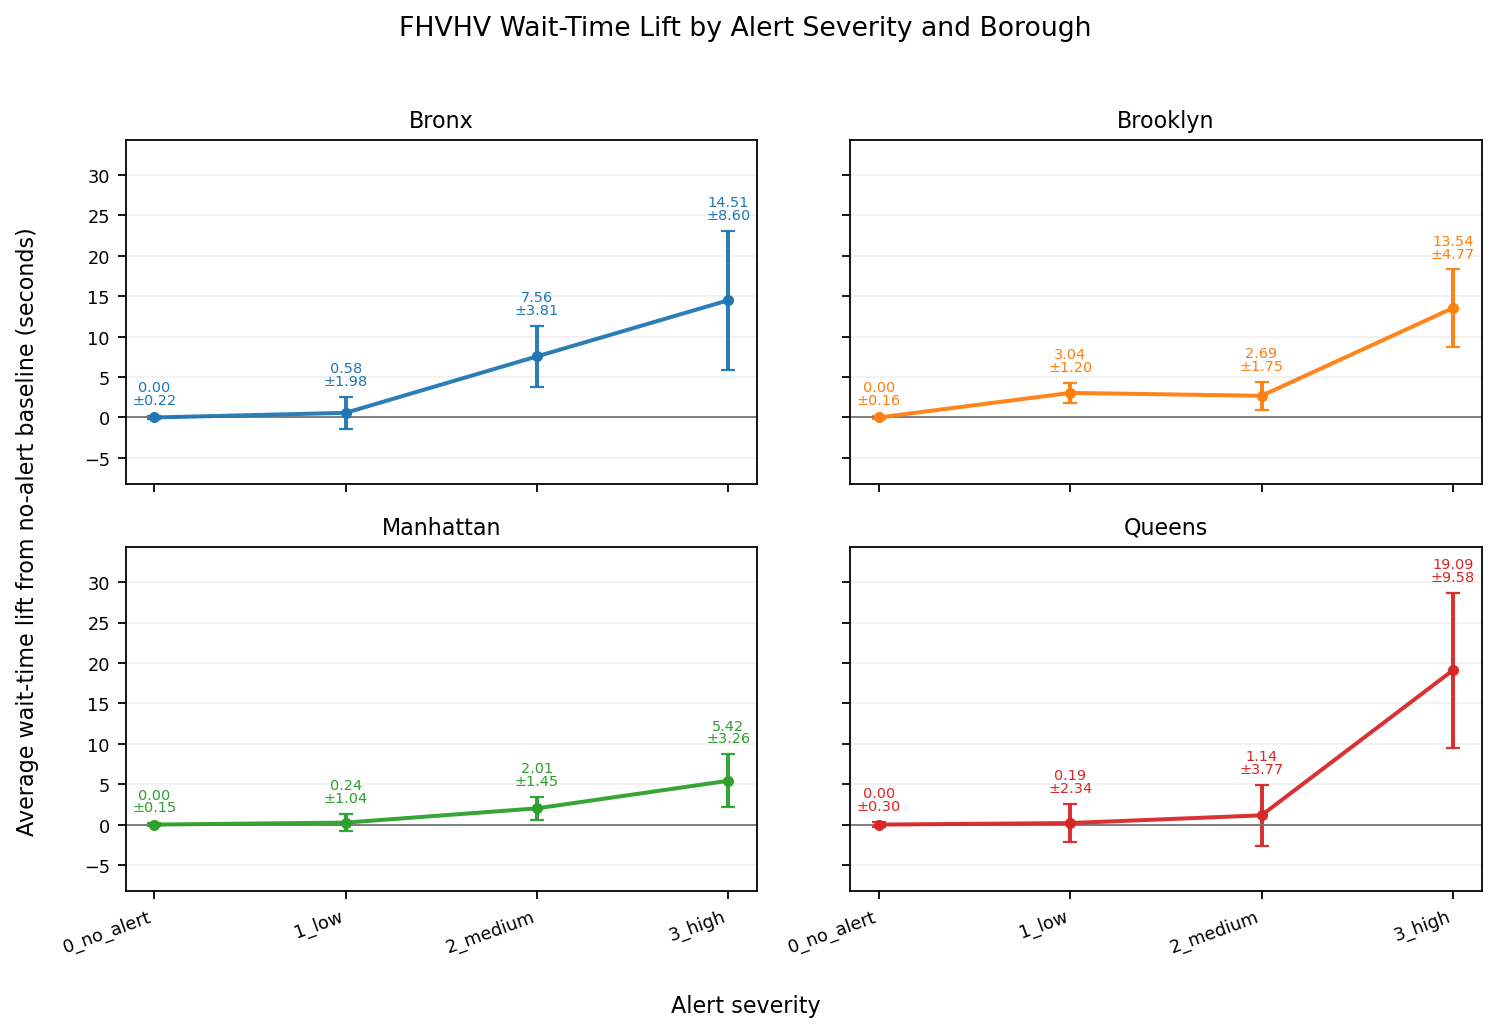

In [11]:
plot_borough_ci(
    metric="avg_taxi_trip_lift",
    ci_metric="ci95_taxi_trip_lift",
    title="Taxi Trip Lift by Alert Severity and Borough",
    ylabel="Average taxi trip lift from no-alert baseline",
    label_points=True,
    label_ci=True
)
plot_borough_ci(
    metric="avg_fhvhv_trip_lift",
    ci_metric="ci95_fhvhv_trip_lift",
    title="FHVHV Trip Lift by Alert Severity and Borough",
    ylabel="Average FHVHV trip lift from no-alert baseline",
    label_points=True,
    label_ci=True
)
plot_borough_ci(
    metric="avg_wait_time_lift",
    ci_metric="ci95_wait_time_lift",
    title="FHVHV Wait-Time Lift by Alert Severity and Borough",
    ylabel="Average wait-time lift from no-alert baseline (seconds)",
    label_points=True,
    label_ci=True
)

In [12]:
(
    alert_effect_df
    .groupBy("borough", "alert_level")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("n_trips_taxi"), 3).alias("avg_taxi_trips"),
        F.round(F.avg("baseline_n_trips_taxi"), 3).alias("avg_baseline_taxi_trips"),
        F.round(F.avg("taxi_trip_lift"), 3).alias("avg_taxi_trip_lift"),
        F.expr("percentile_approx(n_trips_taxi, array(0.5, 0.75, 0.9, 0.99))").alias("taxi_trip_quantiles"),
        F.round(F.avg((F.col("n_trips_taxi") == 0).cast("double")), 3).alias("share_zero_taxi_hours"),
    )
    .orderBy("borough", "alert_level")
    .show(100, truncate=False)
)

+---------+-----------+------------+--------------+-----------------------+------------------+-------------------+---------------------+
|borough  |alert_level|n_zone_hours|avg_taxi_trips|avg_baseline_taxi_trips|avg_taxi_trip_lift|taxi_trip_quantiles|share_zero_taxi_hours|
+---------+-----------+------------+--------------+-----------------------+------------------+-------------------+---------------------+
|Bronx    |0_no_alert |339983      |0.047         |0.047                  |0.0               |[0, 0, 0, 1]       |0.96                 |
|Bronx    |1_low      |4148        |0.071         |0.069                  |0.002             |[0, 0, 0, 1]       |0.945                |
|Bronx    |2_medium   |1998        |0.111         |0.091                  |0.019             |[0, 0, 0, 2]       |0.923                |
|Bronx    |3_high     |559         |0.086         |0.091                  |-0.006            |[0, 0, 0, 1]       |0.921                |
|Brooklyn |0_no_alert |576258      |0.396